# Marine microplastic concentration prediction

Arnab Chakraborty (230102016), Gourab Adhikari (230102003)

This notebook predicts microplastic concentration in sea water (pieces/m3) from where, when and how a
sample was taken, using the NOAA NCEI Marine Microplastics database. The headline question is whether a
model generalises to a study it has never seen, so every model is scored under three splits:

- **Random** 5-fold CV. Near-duplicate samples from one cruise land on both sides of the split.
- **Grouped** 5-fold CV with the study as the group. No study appears in both train and test.

A "study" here is a publication (DOI). Most publications map to one NCEI accession, but one publication
was archived as two accessions with overlapping cruises, and grouping by accession would split it.
- **Chronological** holdout. Train on samples before 2015, test on 2015 onwards.

In [1]:
import json
from collections.abc import Callable
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from matplotlib.colors import LinearSegmentedColormap
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, KFold
from sklearn.neighbors import BallTree, KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier, XGBRegressor

DATA = Path("data/MP_data_S2N_Nyadjro_SD2023.xlsx")
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)
SEED = 0

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
)
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_MUTED,
    "axes.labelcolor": INK,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "font.size": 10,
})
pd.set_option("display.precision", 3)

## 1. The raw workbook

The workbook has a data dictionary sheet and one data sheet with 22,530 records. Column names are
shortened below. Fields that are missing in more than 95% of rows (bottom depth, sediment depth,
transect number and so on) are not carried forward.

In [2]:
raw = pd.read_excel(DATA, sheet_name="Microplastics_AllData")
data = raw.rename(columns={
    "Date (MM/DD/YYYY)": "date",
    "Latitude (degree)": "lat",
    "Longitude(degree)": "lon",
    "Location-Oceans": "ocean",
    "Medium": "medium",
    "Water Sample Depth (m)": "depth",
    "Sampling Method": "method",
    "Mesh size (mm)": "mesh",
    "Microplastics measurement": "conc",
    "Unit": "unit",
    "NCEI Accession No": "accession",
    "DOI": "doi",
    "ORGANIZATION": "organization",
})[["date", "lat", "lon", "ocean", "medium", "depth", "method", "mesh", "conc", "unit", "accession", "doi", "organization"]]

print(f"{len(raw):,} records, {raw['NCEI Accession No'].nunique()} accessions, {raw['ORGANIZATION'].nunique()} organisations")
raw.isna().mean().sort_values(ascending=False).rename("missing").to_frame().T

22,530 records, 79 accessions, 58 organisations


,Transect No,Ocean Bottom Depth (m),Sediment Sample Depth (m),Sampling point on beach,Location-SubRegions,Collecting Time (min),Volunteers Number,Standardized Nurdle Amount,State,Beach Location,...,Date (MM/DD/YYYY),Unit,Concentration class range,Concentration class text,Long Reference,Short Reference,DOI,ORGANIZATION,NCEI Accession No,NCEI Accession No. Link
missing,0.987,0.985,0.983,0.975,0.932,0.742,0.742,0.742,0.725,0.723,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


The concentration column mixes three incompatible units, one per kind of medium. They cannot be converted
into each other, so only the water records reported in pieces/m3 are modelled.

In [3]:
data.groupby(["medium", "unit"], dropna=False).agg(
    records=("conc", "size"),
    with_value=("conc", "count"),
    accessions=("accession", "nunique"),
    median=("conc", "median"),
)

,,records,with_value,accessions,median
medium,unit,,,,
Beach,pieces/m3,671,671,11,1680.000
Beach-Nurdle Patrol,pieces/10 mins,5817,0,1,NaN
Ocean sediment,pieces kg-1 d.w.,508,508,16,52.727
Ocean water,pieces/m3,15534,15534,59,0.009


671 beach records are reported in pieces/m3 too, but they measure a volume of sand, not sea water.
They are dropped, which leaves **ocean water in pieces/m3** as the modelling set.

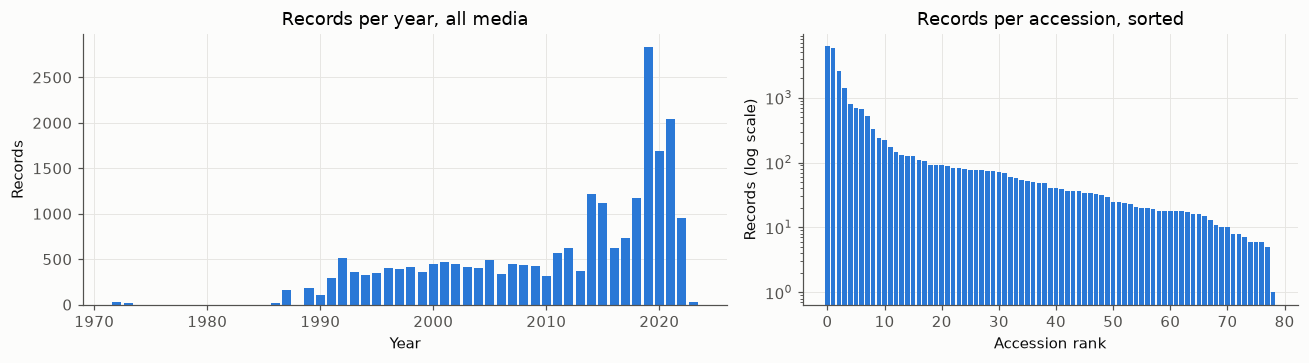

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
per_year = data.groupby(data.date.dt.year).size()
axes[0].bar(per_year.index, per_year.values, color=BLUE, width=0.8)
axes[0].set(title="Records per year, all media", xlabel="Year", ylabel="Records")
per_accession = data.accession.value_counts().to_numpy()
axes[1].bar(np.arange(len(per_accession)), per_accession, color=BLUE, width=0.8)
axes[1].set(title="Records per accession, sorted", xlabel="Accession rank", ylabel="Records (log scale)", yscale="log")
fig.tight_layout()

A handful of studies dominate. The largest accession (Sea Education Association, 1986 to 2008) holds
6,135 records on its own.

## 2. The modelling set

In [5]:
METHOD_FAMILY = {
    "neuston net": "surface net",
    "manta net": "surface net",
    "plankton net": "surface net",
    "avani net": "surface net",
    "intake seawater pump": "pump",
    "surface water intake": "pump",
}
C = 1e-3  # offset for the log target, roughly the smallest non-zero concentration (6.8e-4)

water = data[(data.medium == "Ocean water") & (data.unit == "pieces/m3")].reset_index(drop=True)
method = water.method.str.lower().str.replace("-", " ")
family = method.map(METHOD_FAMILY).fillna("bulk water")
month = water.date.dt.month
df = water.assign(
    method=method,
    method_family=family,
    fam_pump=(family == "pump").astype(float),
    fam_bulk=(family == "bulk water").astype(float),
    year=water.date.dt.year,
    month_sin=np.sin(2 * np.pi * month / 12),
    month_cos=np.cos(2 * np.pi * month / 12),
    log_mesh=np.log10(water.mesh),
    log_depth=np.log1p(water.depth),
    study=water.doi,
    y=np.log10(water.conc + C),
)
print(f"{len(df):,} records, {df.accession.nunique()} accessions, {df.study.nunique()} publications, {df.organization.nunique()} organisations")
df.groupby(["method_family", "method"]).agg(
    records=("y", "size"), accessions=("accession", "nunique"), median_conc=("conc", "median")
).sort_values(["method_family", "records"], ascending=[True, False])

15,534 records, 59 accessions, 58 publications, 43 organisations


records  accessions  median_conc
method_family method                                                   
bulk water    grab sample                 1389           1        0.005
              van dorn sampler             181           1        0.000
              niskin bottle                 81           1        0.001
              stainless steel bucket        80           2      860.000
              aluminum bucket               57           1     1710.000
              ctd rosette sampler           48           1       21.000
              stainless steel sampler       23           1     2600.000
              glass jar                      1           1        0.018
pump          intake seawater pump         284           4        1.000
              surface water intake           5           1     5015.000
surface net   neuston net                10394          14        0.004
              manta net                   2776          32        0.451
              plankton net                 179           6        0.570
              avani net                     36           1        0.063

Sampling methods are grouped into three families. Surface nets are towed at the surface and catch
particles larger than the mesh (mostly 0.33 mm). Bulk water samples (bottles, buckets, grab samples)
are filtered through much finer meshes and report concentrations orders of magnitude higher. Pumps sit
in between. CatBoost also gets the raw method name to check whether the grouping loses anything.

Text(0.5, 1.0, 'Observed concentration, ocean water samples')

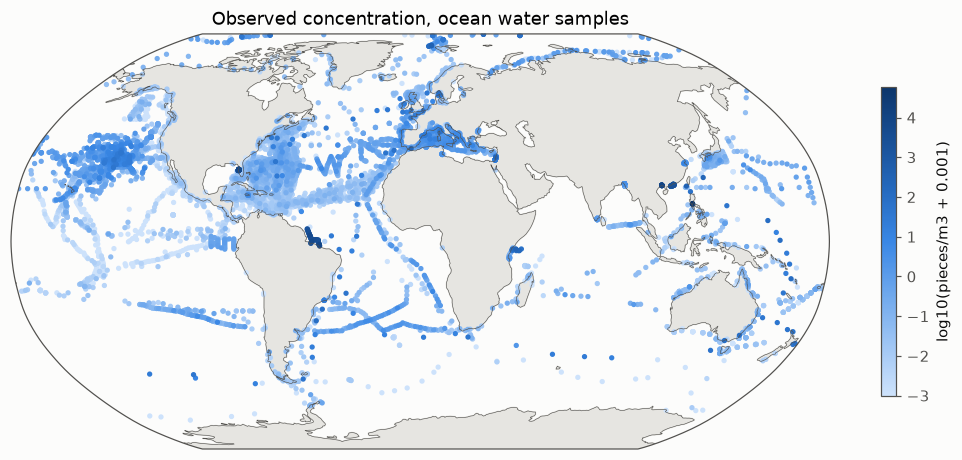

In [6]:
fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(projection=ccrs.Robinson())
ax.set_global()
ax.add_feature(cfeature.LAND, color="#e6e5e1")
ax.coastlines(linewidth=0.4, color=INK_MUTED)
order = df.sort_values("y")
points = ax.scatter(order.lon, order.lat, c=order.y, cmap=SEQUENTIAL, s=6, transform=ccrs.PlateCarree())
fig.colorbar(points, ax=ax, shrink=0.7, label="log10(pieces/m3 + 0.001)")
ax.set_title("Observed concentration, ocean water samples")

Sampling is concentrated in the North Atlantic and North Pacific. The Southern Ocean has 27 records and
the Indian Ocean under 500, so anything the models say about those basins is an extrapolation.

### 2.1 Choosing the target transform

The synopsis proposed `log1p`. That turns out to be a poor fit for this data. 75% of the concentrations
are below 0.1 pieces/m3, and for small x, `log1p(x) ≈ x`, so `log1p` leaves the bulk of the
distribution untransformed. A sample at 0.001 and one at 0.05 differ by a factor of 50 but end up
0.05 apart, while the few samples above 1,000 still dominate the variance.

`log10(conc + 0.001)` spreads the data over its real range. The offset 0.001 pieces/m3 is close to the
smallest non-zero value, so it acts as a detection floor. Zeros map to -3. Errors on this scale read
directly as orders of magnitude, which is the natural unit for a quantity spanning eight of them.

share below 0.1 pieces/m3: 75%, share of zeros: 31%


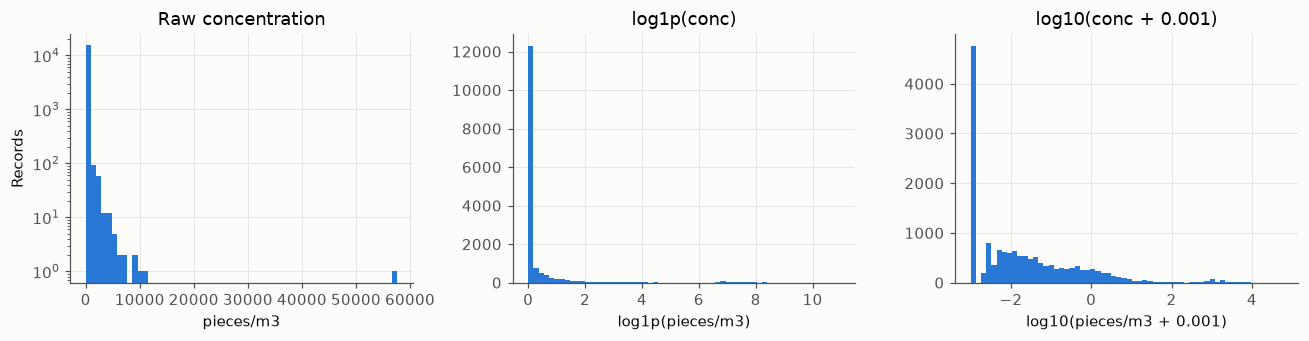

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].hist(df.conc, bins=60, color=BLUE)
axes[0].set(title="Raw concentration", xlabel="pieces/m3", ylabel="Records", yscale="log")
axes[1].hist(np.log1p(df.conc), bins=60, color=BLUE)
axes[1].set(title="log1p(conc)", xlabel="log1p(pieces/m3)")
axes[2].hist(df.y, bins=60, color=BLUE)
axes[2].set(title="log10(conc + 0.001)", xlabel="log10(pieces/m3 + 0.001)")
fig.tight_layout()
print(f"share below 0.1 pieces/m3: {(df.conc < 0.1).mean():.0%}, share of zeros: {(df.conc == 0).mean():.0%}")

### 2.2 How much does study identity explain?

Before fitting anything, it helps to know how much of the variance is between studies rather than
within them. An intercept-only mixed model gives the intraclass correlation (ICC): the share of
target variance that sits in the study-level random intercept. The ICC describes how clustered the data
is. It does not say why.

ICC for study: 0.72


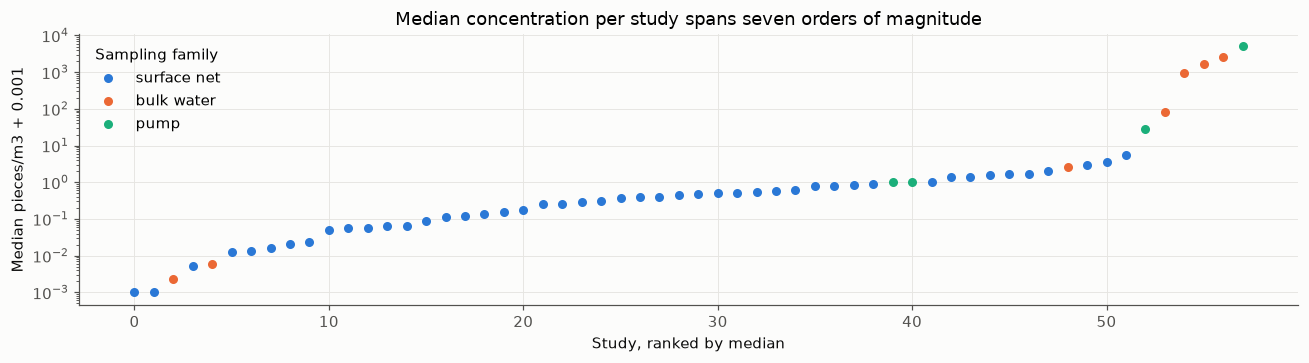

In [8]:
null_mixed = smf.mixedlm("y ~ 1", df, groups=df.study).fit()
between = float(null_mixed.cov_re.iloc[0, 0])
icc = between / (between + null_mixed.scale)
print(f"ICC for study: {icc:.2f}")

study_medians = df.groupby("study").agg(median=("conc", "median"), method=("method_family", "first"), n=("y", "size"))
fig, ax = plt.subplots(figsize=(12, 3.4))
families = {"surface net": BLUE, "bulk water": ORANGE, "pump": AQUA}
ranked = study_medians.sort_values("median").reset_index()
for name, color in families.items():
    part = ranked[ranked.method == name]
    ax.scatter(part.index, part["median"] + C, color=color, s=24, label=name)
ax.set(yscale="log", xlabel="Study, ranked by median", ylabel="Median pieces/m3 + 0.001",
       title="Median concentration per study spans seven orders of magnitude")
ax.legend(title="Sampling family")
fig.tight_layout()

Most of the variance sits between studies. Some of that is physics (fine-mesh bulk samples catch small
fibres that 0.33 mm nets miss), some is where and when each study sampled, and some is study-level
practice that no field in the dataset records. The data cannot separate these cleanly, because each study
tends to use one protocol in one region over a few years.

## 3. Features and validation

Features: latitude, longitude, year, month (as sine and cosine so December sits next to January), sampling
family, log mesh size and log water depth. Medium is constant after filtering, so it is not a feature.
Missing mesh size (0.1%) and depth (4%) are imputed with the training-fold median.

In [9]:
NUMERIC = ["lat", "lon", "year", "month_sin", "month_cos", "log_mesh", "log_depth"]
CATEGORICAL = ["method_family"]
FEATURES = NUMERIC + CATEGORICAL
CUTOFF = 2015

SPLITS = {
    "random": list(KFold(5, shuffle=True, random_state=SEED).split(df)),
    "grouped": list(GroupKFold(5).split(df, groups=df.study)),
    "chrono": [(np.flatnonzero(df.year < CUTOFF), np.flatnonzero(df.year >= CUTOFF))],
}
for scheme, folds in SPLITS.items():
    sizes = [len(test) for _, test in folds]
    print(f"{scheme:>8}: {len(folds)} fold(s), test sizes {sizes}")
pre, post = df[df.year < CUTOFF], df[df.year >= CUTOFF]
seen = post.study.isin(pre.study)
print(f"chrono: {pre.study.nunique()} studies before {CUTOFF}, {post.study.nunique()} after, "
      f"{post[seen].study.nunique()} in both. {seen.sum():,} of {len(post):,} test rows come from studies seen in training")

  random: 5 fold(s), test sizes [3107, 3107, 3107, 3107, 3106]
 grouped: 5 fold(s), test sizes [6135, 2530, 2290, 2289, 2290]
  chrono: 1 fold(s), test sizes [4195]
chrono: 16 studies before 2015, 48 after, 6 in both. 1,800 of 4,195 test rows come from studies seen in training


Grouped folds are uneven because one study holds 39% of the rows. The chronological test set mixes two
things: most of its studies are new, but a large share of its rows come from long-running studies that
also appear before 2015. Its results are therefore also broken down by seen and unseen studies.

Every model is a function that takes a training frame and returns a predictor. Each model gets the
same folds.

In [10]:
Predictor = Callable[[pd.DataFrame], np.ndarray]
Model = Callable[[pd.DataFrame], Predictor]


def preprocessor() -> ColumnTransformer:
    return ColumnTransformer([
        ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
    ])


def clip_to_range(train: pd.DataFrame) -> Callable[[pd.DataFrame], pd.DataFrame]:
    """Clips numeric features to the training range, so models that extrapolate (linear, splines) stay flat
    outside it. Trees already behave this way."""
    low, high = train[NUMERIC].min(), train[NUMERIC].max()
    return lambda frame: frame.assign(**{c: frame[c].clip(low[c], high[c]) for c in NUMERIC})


def sklearn_model(estimator) -> Model:
    def fit(train: pd.DataFrame) -> Predictor:
        clip = clip_to_range(train)
        pipe = make_pipeline(preprocessor(), clone(estimator)).fit(train[FEATURES], train.y)
        return lambda test: pipe.predict(clip(test)[FEATURES])
    return fit


def fit_study_mean(train: pd.DataFrame) -> Predictor:
    """Predicts the training mean of the sample's own study. Falls back to the global mean for unseen studies."""
    means = train.groupby("study").y.mean()
    return lambda test: test.study.map(means).fillna(train.y.mean()).to_numpy()


def fit_knn(train: pd.DataFrame) -> Predictor:
    """Inverse-distance weighted average of the 15 nearest samples on the sphere. Location only."""
    knn = KNeighborsRegressor(n_neighbors=15, weights="distance", metric="haversine", algorithm="ball_tree")
    knn.fit(np.radians(train[["lat", "lon"]]), train.y)
    return lambda test: knn.predict(np.radians(test[["lat", "lon"]]))


MIXED_TERMS = ["cr(lat, df=6, constraints='center')", "cr(lon, df=6, constraints='center')",
               "cr(year, df=4, constraints='center')", "month_sin", "month_cos", "log_mesh", "log_depth"]


def fit_mixed(train: pd.DataFrame) -> Predictor:
    """Additive mixed model: natural cubic splines of lat, lon and year plus a random intercept per study.

    Studies seen in training get their estimated random intercept added; unseen studies get the
    population-level prediction.
    """
    medians = train[NUMERIC].median()
    clip = clip_to_range(train)

    def prepare(frame: pd.DataFrame) -> pd.DataFrame:
        return clip(frame.fillna({c: medians[c] for c in NUMERIC}))

    families = [c for c in ("fam_pump", "fam_bulk") if train[c].nunique() > 1]
    formula = "y ~ " + " + ".join(MIXED_TERMS + families)
    result = smf.mixedlm(formula, prepare(train), groups=train.study).fit(method="lbfgs")
    offsets = pd.Series({g: v.iloc[0] for g, v in result.random_effects.items()})

    def predict(test: pd.DataFrame) -> np.ndarray:
        return np.asarray(result.predict(prepare(test))) + test.study.map(offsets).fillna(0).to_numpy()
    return predict


BOOSTER_DEFAULTS = dict(n_estimators=500, learning_rate=0.05, random_state=SEED, n_jobs=4)
CATBOOST_FEATURES = FEATURES + ["method"]


def train_catboost(train: pd.DataFrame, features: list[str] = CATBOOST_FEATURES, **params) -> CatBoostRegressor:
    cats = train[features].select_dtypes(exclude="number").columns.tolist()
    model = CatBoostRegressor(
        **{"iterations": 500, "learning_rate": 0.05, "random_seed": SEED, "thread_count": 4, "verbose": 0} | params
    )
    return model.fit(train[features], train.y, cat_features=cats)


def fit_catboost(train: pd.DataFrame, features: list[str] = CATBOOST_FEATURES, **params) -> Predictor:
    model = train_catboost(train, features, **params)
    return lambda test: model.predict(test[features])


def fit_hurdle(train: pd.DataFrame) -> Predictor:
    """Two-part XGBoost: P(conc > 0) times the positive-part regression, plus P(conc = 0) times the zero level."""
    positive = train[train.conc > 0]
    classifier = make_pipeline(preprocessor(), XGBClassifier(**BOOSTER_DEFAULTS)).fit(train[FEATURES], train.conc > 0)
    regressor = make_pipeline(preprocessor(), XGBRegressor(**BOOSTER_DEFAULTS)).fit(positive[FEATURES], positive.y)

    def predict(test: pd.DataFrame) -> np.ndarray:
        p = classifier.predict_proba(test[FEATURES])[:, 1]
        return p * regressor.predict(test[FEATURES]) + (1 - p) * np.log10(C)
    return predict


MODELS: dict[str, Model] = {
    "Study mean only": fit_study_mean,
    "Linear regression": sklearn_model(LinearRegression()),
    "Additive mixed model": fit_mixed,
    "Spatial kNN": fit_knn,
    "Random forest": sklearn_model(RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=4, random_state=SEED)),
    "XGBoost": sklearn_model(XGBRegressor(**BOOSTER_DEFAULTS, max_depth=6)),
    "LightGBM": sklearn_model(LGBMRegressor(**BOOSTER_DEFAULTS, verbose=-1)),
    "CatBoost": fit_catboost,
    "XGBoost hurdle": fit_hurdle,
}

"Study mean only" is a reference point, not a candidate. It knows nothing except which study a sample
came from. Under random CV it shows how far study identity alone gets you. Under grouped CV it collapses
to the global mean. The spatial kNN baseline asks whether a model beats "average the nearest samples".

### 3.1 Metrics

The primary metrics are on the log10 scale: R², MAE and RMSE, plus the share of predictions within one
log10 unit of the truth. Because of the 0.001 offset, "within one log unit" is measured on
`conc + 0.001`, so a true zero and a prediction of 0.009 count as a match.

"Study MAE" averages the MAE of each study, so a small study counts as much as the 6,000-row one. That is
the closer match to "how wrong will the model be on the next study".

Raw-scale MAE and RMSE use `10**pred - 0.001`. A back-transformed log prediction is not an estimate of the
raw mean, and raw RMSE is dominated by a handful of samples above 1,000 pieces/m3, so raw metrics are
secondary.

In [11]:
def metrics(y: np.ndarray, pred: np.ndarray) -> dict[str, float]:
    err = pred - y
    raw_err = np.clip(10**pred - C, 0, None) - (10**y - C)
    return {
        "R2": 1 - np.sum(err**2) / np.sum((y - y.mean()) ** 2),
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err**2)),
        "within 1 log": np.mean(np.abs(err) <= 1),
        "raw MAE": np.mean(np.abs(raw_err)),
        "raw RMSE": np.sqrt(np.mean(raw_err**2)),
    }


def score(pred: pd.Series) -> dict[str, float]:
    """Metrics for a series of out-of-fold predictions indexed like df. NaN entries are skipped."""
    pred = pred.dropna()
    y = df.y.loc[pred.index]
    study_mae = (pred - y).abs().groupby(df.study.loc[pred.index]).mean().mean()
    return metrics(y.to_numpy(), pred.to_numpy()) | {"study MAE": study_mae}


def out_of_fold(model: Model, scheme: str) -> pd.Series:
    pred = pd.Series(np.nan, index=df.index)
    for train_idx, test_idx in SPLITS[scheme]:
        pred.iloc[test_idx] = model(df.iloc[train_idx])(df.iloc[test_idx])
    return pred


SHOWN = ["R2", "MAE", "study MAE", "within 1 log"]

## 4. Model comparison

In [12]:
predictions = {(name, scheme): out_of_fold(model, scheme) for name, model in MODELS.items() for scheme in SPLITS}
results = pd.DataFrame(
    [{"model": name, "scheme": scheme} | score(pred) for (name, scheme), pred in predictions.items()]
).set_index(["model", "scheme"])
results.to_csv(ARTIFACTS / "model_comparison.csv")
results[SHOWN].unstack("scheme").reindex(MODELS).swaplevel(axis=1)[["random", "grouped", "chrono"]]

scheme               random                               grouped         \
                         R2    MAE study MAE within 1 log      R2    MAE   
model                                                                      
Study mean only       0.581  0.644     0.509        0.848  -0.207  1.168   
Linear regression     0.344  0.846     1.102        0.652  -0.005  1.070   
Additive mixed model  0.637  0.591     0.512        0.869  -0.559  1.329   
Spatial kNN           0.620  0.520     0.611        0.868  -0.195  1.054   
Random forest         0.743  0.425     0.478        0.919  -0.102  0.952   
XGBoost               0.735  0.455     0.477        0.917   0.038  0.918   
LightGBM              0.740  0.455     0.486        0.918   0.207  0.872   
CatBoost              0.720  0.501     0.558        0.904   0.245  0.881   
XGBoost hurdle        0.746  0.446     0.492        0.917   0.172  0.896   

scheme                                      chrono                   \
                     study MAE within 1 log     R2    MAE study MAE   
model                                                                 
Study mean only          1.743        0.437 -0.573  1.575     1.920   
Linear regression        1.196        0.512 -8.511  2.618     3.597   
Additive mixed model     1.024        0.447 -3.925  1.631     2.359   
Spatial kNN              1.215        0.614 -0.299  1.320     1.483   
Random forest            1.052        0.707 -0.060  1.131     1.453   
XGBoost                  1.007        0.695 -0.082  1.145     1.525   
LightGBM                 1.016        0.698  0.027  1.060     1.354   
CatBoost                 1.027        0.665 -0.006  1.125     1.339   
XGBoost hurdle           1.030        0.689 -0.052  1.116     1.409   

scheme                             
                     within 1 log  
model                              
Study mean only             0.460  
Linear regression           0.428  
Additive mixed model        0.678  
Spatial kNN                 0.545  
Random forest               0.647  
XGBoost                     0.636  
LightGBM                    0.677  
CatBoost                    0.617  
XGBoost hurdle              0.641

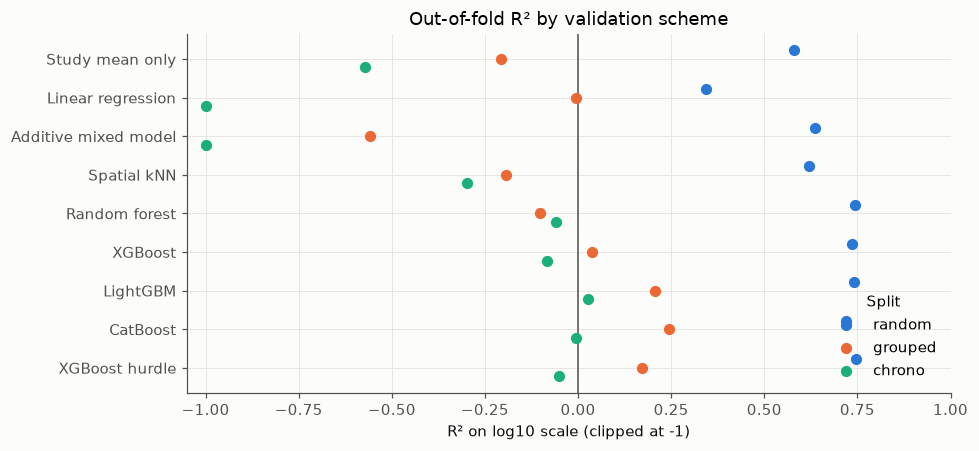

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(MODELS)
rows = np.arange(len(names))
for offset, (scheme, color) in zip((-0.22, 0, 0.22), [("random", BLUE), ("grouped", ORANGE), ("chrono", AQUA)]):
    values = [results.loc[(n, scheme), "R2"] for n in names]
    ax.scatter(np.clip(values, -1, None), rows + offset, color=color, s=40, label=scheme, zorder=3)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_yticks(rows, names)
ax.invert_yaxis()
ax.set(xlabel="R² on log10 scale (clipped at -1)", title="Out-of-fold R² by validation scheme", xlim=(-1.05, 1))
ax.legend(title="Split", loc="lower right")
fig.tight_layout()

The grouped R² above is pooled: all out-of-fold predictions scored together. Per-fold R² is shown below.
Each fold holds out different studies, and each fold's R² uses its own variance as the denominator, so
the fold mean is not the same quantity as the pooled score. Pooled R² is the headline. The per-fold
spread shows how much it depends on which studies are held out.

In [14]:
pd.DataFrame(
    {name: [score(predictions[name, "grouped"].iloc[t])["R2"] for _, t in SPLITS["grouped"]] for name in MODELS},
    index=[f"fold {i + 1}" for i in range(5)],
).T.assign(**{"fold mean": lambda t: t.mean(axis=1), "pooled": results.xs("grouped", level="scheme").R2})

,fold 1,fold 2,fold 3,fold 4,fold 5,fold mean,pooled
Study mean only,-1.409,-1.207,-0.036,-0.432,-1.131,-0.843,-0.207
Linear regression,-0.853,-2.193,0.243,0.155,-0.759,-0.681,-0.005
Additive mixed model,-3.440,-8.780,0.456,0.204,0.116,-2.289,-0.559
Spatial kNN,-0.904,-4.458,-0.067,0.277,-0.734,-1.177,-0.195
Random forest,-0.500,-0.008,-1.953,0.124,-0.133,-0.494,-0.102
XGBoost,-0.506,-0.570,-1.219,0.362,-0.054,-0.398,0.038
LightGBM,-0.374,-0.272,-0.340,0.186,-0.050,-0.170,0.207
CatBoost,-0.175,-0.284,-0.204,0.324,-0.215,-0.111,0.245
XGBoost hurdle,-0.331,-0.440,-0.828,0.477,0.042,-0.216,0.172


Chronological holdout, split by whether the test row's study also has samples before 2015.

In [15]:
seen_study = df.study.isin(df.loc[df.year < CUTOFF, "study"])
pd.DataFrame({
    name: {
        (group, metric): score(predictions[name, "chrono"].where(mask))[metric]
        for group, mask in [("seen study", seen_study), ("unseen study", ~seen_study)]
        for metric in ("R2", "MAE")
    }
    for name in MODELS
}).T

seen study        unseen study       
                             R2    MAE           R2    MAE
Study mean only          -0.031  0.756       -1.379  2.191
Linear regression        -0.200  0.802      -14.592  3.983
Additive mixed model      0.145  0.688       -7.019  2.340
Spatial kNN               0.032  0.725       -0.938  1.767
Random forest             0.168  0.679       -0.570  1.471
XGBoost                   0.114  0.702       -0.595  1.478
LightGBM                  0.264  0.643       -0.448  1.374
CatBoost                  0.229  0.656       -0.495  1.477
XGBoost hurdle            0.128  0.687       -0.548  1.438

What the comparison shows:

- **Random CV flatters every model.** The tree ensembles reach R² ≈ 0.74 on random folds and land around
  zero on new studies. Even "study mean only", which knows nothing but the study label, gets 0.58 on
  random folds.
- **Under grouped CV, CatBoost and LightGBM are the only models clearly above zero** (pooled R² 0.25 and
  0.21). Every model has a negative fold mean, so on a typical held-out block of studies, predicting the
  training mean would beat them. Roughly 70% of grouped predictions still land within one order of
  magnitude, against about 92% on random folds.
- **The chronological holdout is close to R² = 0 for every tree model.** On rows from studies seen before
  2015 the trees keep some skill (R² 0.11 to 0.26). On unseen studies they fall to about -0.5.
- **Linear regression and the mixed model fail for specific reasons.** Before 2015, every bulk-water
  sample comes from one study with one mesh size (0.45 µm), so the bulk-water flag and mesh size are
  collinear. OLS fits large offsetting coefficients that explode on the chronological holdout, where new
  bulk-water studies use other meshes. The mixed model
  puts most of each study's level into its random intercept, so for an unseen study it predicts an
  "average study" and misses the very low SEA neuston studies (folds 1 and 2) badly. This says these two
  fits are unstable on this data. It does not show that linear or additive models are worse in general.
- **Spatial kNN** is close to the trees on random folds and well below them on new studies. That is what
  you would expect if nearby samples mostly come from the same cruise.

## 5. Which features carry information that transfers?

CatBoost is refit with different feature sets under random and grouped CV. Location and time only,
sampling protocol only, all features, all features with the sampling family in place of the raw method
name, and all features plus the study ID as a categorical feature. Adding the study ID can only help when
the test study was seen in training, so the gap it opens between random and grouped CV shows how much of
the random-split score is study recognition.

In [16]:
LOCATION_TIME = ["lat", "lon", "year", "month_sin", "month_cos"]
PROTOCOL = ["log_mesh", "log_depth", "method_family", "method"]
ABLATIONS = {
    "location and time only": LOCATION_TIME,
    "sampling protocol only": PROTOCOL,
    "all features": CATBOOST_FEATURES,
    "all features, family not raw method": FEATURES,
    "all features + study ID": CATBOOST_FEATURES + ["study"],
}
pd.DataFrame({
    (name, scheme): score(out_of_fold(lambda t, f=features: fit_catboost(t, f), scheme))
    for name, features in ABLATIONS.items()
    for scheme in ("random", "grouped")
}).T[SHOWN].unstack()

R2            MAE        study MAE  \
                                    grouped random grouped random   grouped   
all features                          0.245  0.720   0.881  0.501     1.027   
all features + study ID               0.250  0.721   0.885  0.500     0.980   
all features, family not raw method   0.271  0.718   0.860  0.503     0.991   
location and time only               -0.089  0.680   1.055  0.539     1.305   
sampling protocol only                0.069  0.563   0.967  0.668     1.124   

                                           within 1 log         
                                    random      grouped random  
all features                         0.558        0.665  0.904  
all features + study ID              0.558        0.662  0.903  
all features, family not raw method  0.561        0.673  0.901  
location and time only               0.675        0.580  0.877  
sampling protocol only               0.675        0.667  0.839

Location and time alone reach R² 0.68 on random folds and drop below zero on new studies. On random
folds, coordinates and dates pick out the cruise a sample came from, which is also why adding the study
ID changes nothing there: the model can already tell. Sampling protocol alone transfers a little (grouped
R² 0.07). The full feature set transfers best (0.25 to 0.27), so location and protocol carry some
information jointly that neither carries alone. Grouping the 14 raw methods into three families does not
lose anything. It scores slightly higher than the raw names.

## 6. Genetic algorithm hyperparameter search

CatBoost is tuned because it has the best grouped-CV score. The search only sees data from before 2015
and scores candidates with 4-fold grouped CV on those years. The tuned parameters are then scored on the
2015-onwards holdout. That holdout is not a pristine test set: section 4 already looked at it, and the
choice of CatBoost used grouped CV over all years. Treat the holdout numbers as exploratory.

Each individual is a vector of genes in [0, 1], decoded into CatBoost parameters below. Fitness is the
RMSE of the pooled out-of-fold predictions, so every sample counts equally, matching how the other
scores are reported. Each generation keeps the two best individuals unchanged
(elitism) and fills the rest with children: parents are picked by 3-way tournament, genes are blended
with random weights, and each gene mutates with probability 0.2. A random search with the same number of
evaluations is the control. Without it, there is no evidence that the GA adds anything.

In [17]:
SPACE = {  # name: (low, high, scale)
    "depth": (3, 8, "int"),
    "learning_rate": (0.01, 0.3, "log"),
    "iterations": (200, 1000, "int"),
    "l2_leaf_reg": (0.1, 30, "log"),
    "random_strength": (0.1, 10, "log"),
    "subsample": (0.5, 1.0, "linear"),
    "rsm": (0.5, 1.0, "linear"),
}
dev = df[df.year < CUTOFF]
holdout = df[df.year >= CUTOFF]
DEV_FOLDS = list(GroupKFold(4).split(dev, groups=dev.study))


def decode(genes: np.ndarray) -> dict[str, float | int | str]:
    params: dict[str, float | int | str] = {"bootstrap_type": "Bernoulli"}
    for gene, (name, (low, high, scale)) in zip(genes, SPACE.items()):
        if scale == "log":
            params[name] = float(low * (high / low) ** gene)
        else:
            value = low + gene * (high - low)
            params[name] = round(value) if scale == "int" else float(value)
    return params


def cv_rmse(params: dict) -> float:
    pred = np.empty(len(dev))
    for train_idx, test_idx in DEV_FOLDS:
        pred[test_idx] = fit_catboost(dev.iloc[train_idx], **params)(dev.iloc[test_idx])
    return float(np.sqrt(np.mean((pred - dev.y.to_numpy()) ** 2)))


def evaluated(genes: np.ndarray, generation: int) -> dict:
    params = decode(genes)
    return {"generation": generation, "genes": genes.tolist(), "params": params, "rmse": cv_rmse(params)}


def tournament(population: np.ndarray, fitness: np.ndarray, rng: np.random.Generator, k: int = 3) -> np.ndarray:
    contenders = rng.choice(len(population), k, replace=False)
    return population[contenders[np.argmin(fitness[contenders])]]


def genetic_search(rng: np.random.Generator, size: int = 12, generations: int = 10, elite: int = 2,
                   mutation: float = 0.2) -> list[dict]:
    history = [evaluated(g, 0) for g in rng.random((size, len(SPACE)))]
    population = np.array([h["genes"] for h in history])
    fitness = np.array([h["rmse"] for h in history])
    for generation in range(1, generations):
        keep = np.argsort(fitness)[:elite]
        children, child_fitness = list(population[keep]), list(fitness[keep])
        while len(children) < size:
            a, b = tournament(population, fitness, rng), tournament(population, fitness, rng)
            weights = rng.random(len(SPACE))
            child = weights * a + (1 - weights) * b
            child += (rng.random(len(SPACE)) < mutation) * rng.normal(0, 0.15, len(SPACE))
            history.append(evaluated(np.clip(child, 0, 1), generation))
            children.append(np.array(history[-1]["genes"]))
            child_fitness.append(history[-1]["rmse"])
        population, fitness = np.array(children), np.array(child_fitness)
    return history


def random_search(rng: np.random.Generator, evaluations: int) -> list[dict]:
    return [evaluated(rng.random(len(SPACE)), 0) for _ in range(evaluations)]


GA_SETTINGS = dict(size=12, generations=10, elite=2, mutation=0.2)
SEARCH_CONFIG = json.loads(json.dumps({
    "space": SPACE, "ga": GA_SETTINGS, "seed": SEED, "dev_rows": len(dev), "dev_studies": dev.study.nunique(),
}))


def cached(path: Path, compute: Callable[[], list[dict]]) -> list[dict]:
    """Runs a slow search once and reuses the saved result for as long as SEARCH_CONFIG is unchanged."""
    if path.exists() and (saved := json.loads(path.read_text()))["config"] == SEARCH_CONFIG:
        return saved["history"]
    history = compute()
    path.write_text(json.dumps({"config": SEARCH_CONFIG, "history": history}, indent=1))
    return history


ga_history = cached(ARTIFACTS / "ga_search.json", lambda: genetic_search(np.random.default_rng(SEED), **GA_SETTINGS))
rs_history = cached(ARTIFACTS / "random_search.json",
                    lambda: random_search(np.random.default_rng(SEED + 1), len(ga_history)))
default_rmse = cv_rmse({})
print(f"{len(ga_history)} evaluations per search. Default CatBoost dev RMSE: {default_rmse:.3f}")

102 evaluations per search. Default CatBoost dev RMSE: 0.977


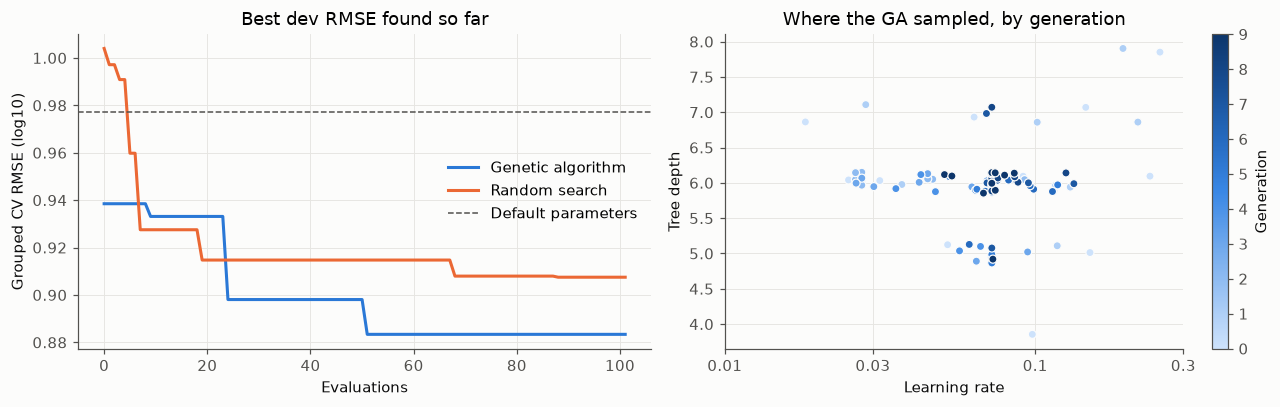

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for history, label, color in [(ga_history, "Genetic algorithm", BLUE), (rs_history, "Random search", ORANGE)]:
    axes[0].plot(np.minimum.accumulate([h["rmse"] for h in history]), color=color, label=label)
axes[0].axhline(default_rmse, color=INK_MUTED, linewidth=1, linestyle="--", label="Default parameters")
axes[0].set(title="Best dev RMSE found so far", xlabel="Evaluations", ylabel="Grouped CV RMSE (log10)")
axes[0].legend()

ga_frame = pd.DataFrame([h["params"] | {"generation": h["generation"], "rmse": h["rmse"]} for h in ga_history])
points = axes[1].scatter(ga_frame.learning_rate, ga_frame.depth + np.random.default_rng(0).uniform(-0.15, 0.15, len(ga_frame)),
                         c=ga_frame.generation, cmap=SEQUENTIAL, s=28, edgecolor="#fcfcfb", linewidth=0.8)
fig.colorbar(points, ax=axes[1], label="Generation")
axes[1].set(xscale="log", title="Where the GA sampled, by generation", xlabel="Learning rate", ylabel="Tree depth")
axes[1].set_xticks([0.01, 0.03, 0.1, 0.3], ["0.01", "0.03", "0.1", "0.3"], minor=False)
axes[1].set_xticks([], minor=True)
fig.tight_layout()

In [19]:
def best(history: list[dict]) -> dict:
    return min(history, key=lambda h: h["rmse"])


candidates = {
    "Default": {"params": {}, "rmse": default_rmse},
    "Random search": best(rs_history),
    "Genetic algorithm": best(ga_history),
}
chosen = min(candidates, key=lambda name: candidates[name]["rmse"])
print(f"Lowest dev RMSE: {chosen}. Its parameters are used for the final model.")
display(pd.DataFrame({name: c["params"] for name, c in candidates.items()}).T.drop(columns="bootstrap_type"))
pd.DataFrame({
    name: {"dev CV RMSE": c["rmse"]} | metrics(holdout.y.to_numpy(), fit_catboost(dev, **c["params"])(holdout))
    for name, c in candidates.items()
}).T[["dev CV RMSE", "R2", "MAE", "RMSE", "within 1 log"]]

Lowest dev RMSE: Genetic algorithm. Its parameters are used for the final model.


,depth,learning_rate,iterations,l2_leaf_reg,random_strength,subsample,rsm
Default,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Random search,6,0.011,282,1.985,5.152,0.716,0.502
Genetic algorithm,6,0.072,691,0.572,6.001,0.805,0.547


,dev CV RMSE,R2,MAE,RMSE,within 1 log
Default,0.977,-0.006,1.125,1.624,0.617
Random search,0.907,0.044,1.091,1.582,0.601
Genetic algorithm,0.883,0.022,1.081,1.601,0.657


The GA found a better development score than random search with the same 102 evaluations (RMSE 0.883
against 0.907, default 0.977), and its best configurations settle in a band around depth 6 with a
moderate learning rate. That improvement barely reaches the holdout. All three configurations sit near
R² = 0 there, and the GA's main gain is a higher share of predictions within one order of magnitude.
This is one run with one seed, so it does not show the GA is better than random search in general.
The lesson here is that tuning cannot fix a gap that comes from the data: the model is limited by what
transfers between studies, not by its hyperparameters.

## 7. SHAP explanations

CatBoost with the parameters that scored best in development is refit on every water record and explained
with exact TreeSHAP values. Categorical features are shown as integer codes in the beeswarm. SHAP explains
what this fitted model does. It does not show that a feature causes higher concentrations.

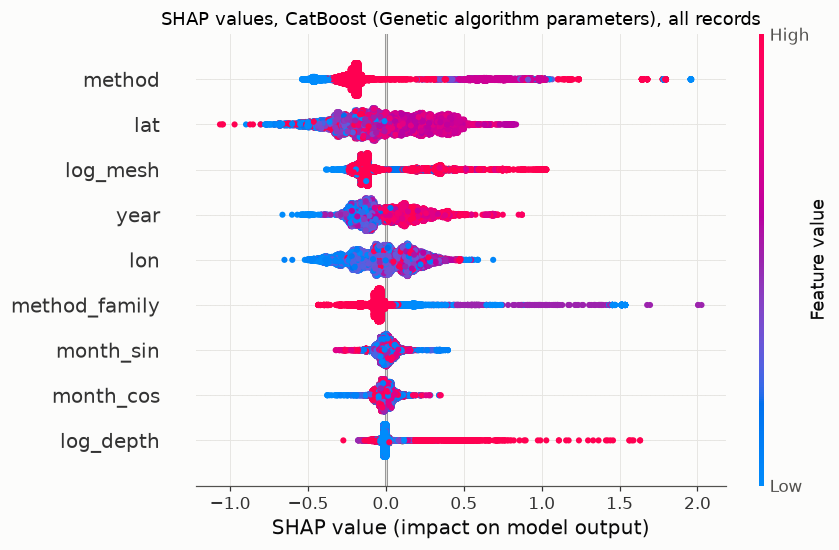

In [20]:
final = train_catboost(df, **candidates[chosen]["params"])
X = df[CATBOOST_FEATURES]
shap_values = shap.TreeExplainer(final)(X)
codes = X.assign(**{c: X[c].astype("category").cat.codes for c in ("method_family", "method")})
shap.summary_plot(shap_values.values, codes, max_display=10, show=False)
plt.title(f"SHAP values, CatBoost ({chosen} parameters), all records")
plt.tight_layout()

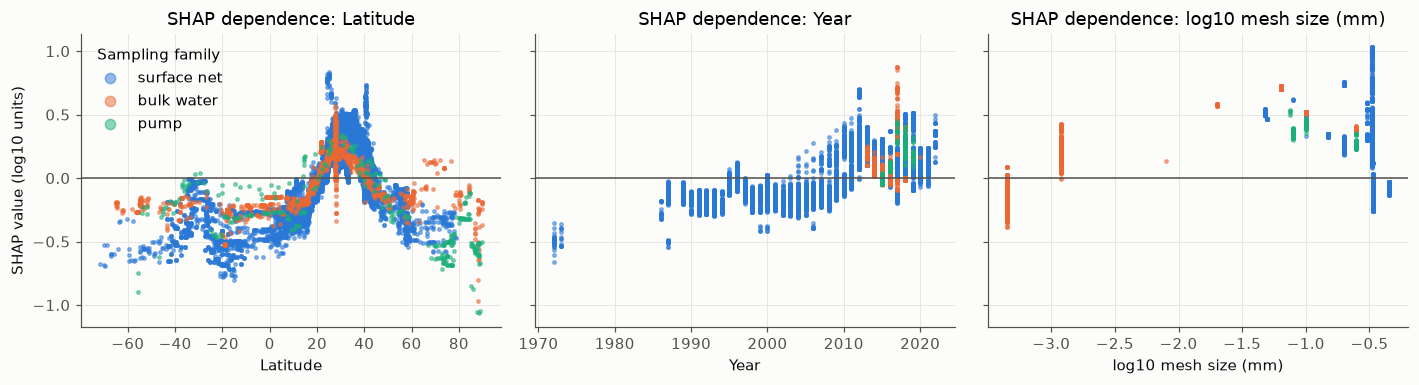

In [21]:
contributions = pd.DataFrame(shap_values.values, columns=CATBOOST_FEATURES, index=df.index)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, feature, label in zip(axes, ["lat", "year", "log_mesh"], ["Latitude", "Year", "log10 mesh size (mm)"]):
    for name, color in families.items():
        part = df.method_family == name
        ax.scatter(df.loc[part, feature], contributions.loc[part, feature], color=color, s=5, alpha=0.5, label=name)
    ax.axhline(0, color=INK_MUTED, linewidth=1)
    ax.set(xlabel=label, title=f"SHAP dependence: {label}")
axes[0].set_ylabel("SHAP value (log10 units)")
axes[0].legend(title="Sampling family", markerscale=3)
fig.tight_layout()

Sampling method, latitude and mesh size carry the largest contributions. The latitude curve peaks between
about 20° and 45° N, where the North Atlantic and North Pacific subtropical gyres are. That is where
floating plastic is known to accumulate, and also where the largest studies sampled. The year curve
rises by roughly one order of magnitude from the 1970s to the 2010s. That is harder to read: Law et al.
(2010), the largest study in this data, found no clear trend in its own North Atlantic series, so the
rise may come from newer studies using different methods rather than from more plastic.

The mesh curve is the warning sign. Finer meshes should catch more particles, yet the finest mesh in the
data (0.45 µm) gets a negative contribution. Nearly all of those samples are grab samples from a single
study with very low counts, so the model has learned that study, not the physics of mesh size.

The single highest prediction, broken down feature by feature:

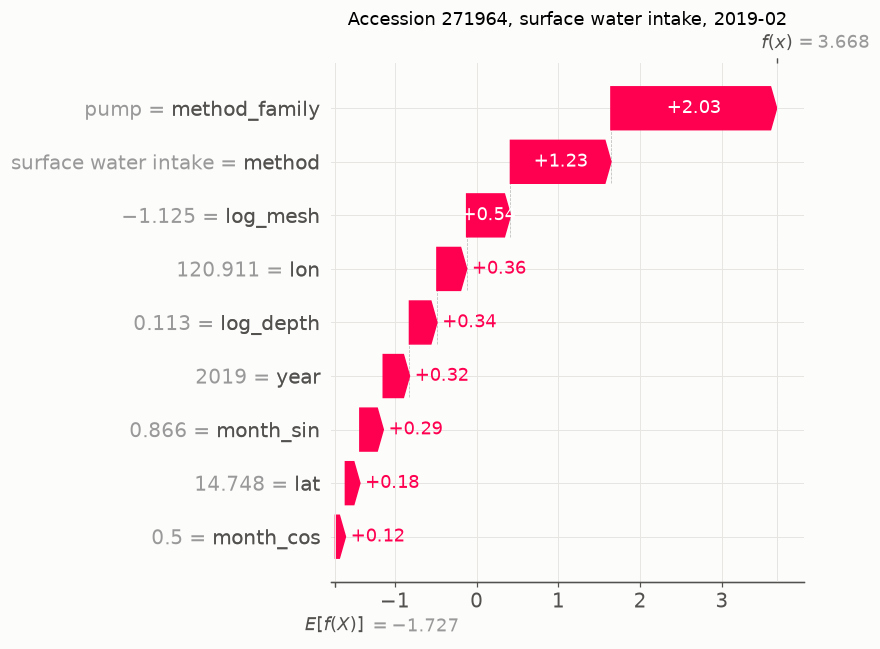

In [22]:
top = int(np.argmax(final.predict(X)))
shap.plots.waterfall(shap_values[top], show=False)
plt.title(f"Accession {df.accession[top]}, {df.method[top]}, {df.date[top]:%Y-%m}")
plt.tight_layout()
plt.show()

### 7.1 SHAP against the study offsets from the mixed model

The intercept-only mixed model from section 2.2 estimates one offset per study: how far that study sits
above or below the global mean. Below, each point is a study. The x axis is its offset. The y axis is the
average SHAP contribution of one feature group across that study's samples.

This is descriptive. It shows which inputs the fitted model routes study-level differences through. It
cannot separate geography from study recognition, because coordinates and dates can pick out a cruise
as easily as mesh size can, and a model fitted to these outcomes will track the study offsets by
construction. The grouped-CV ablations in section 5 are the test of what transfers to new studies.

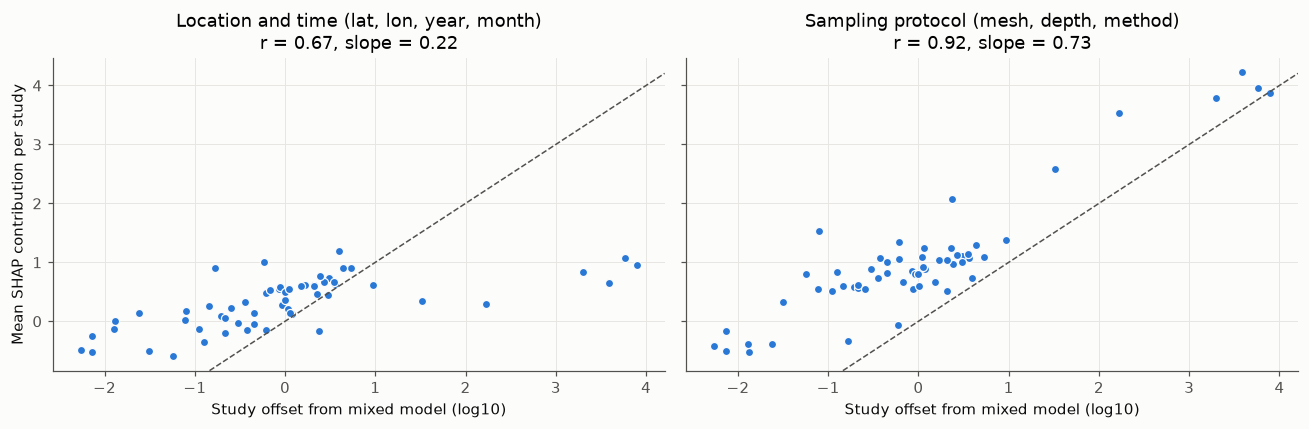

In [23]:
offsets = pd.Series({g: v.iloc[0] for g, v in null_mixed.random_effects.items()})
GROUPS = {
    "Location and time (lat, lon, year, month)": ["lat", "lon", "year", "month_sin", "month_cos"],
    "Sampling protocol (mesh, depth, method)": ["log_mesh", "log_depth", "method_family", "method"],
}
per_study = pd.DataFrame({name: contributions[cols].sum(axis=1) for name, cols in GROUPS.items()}).groupby(df.study).mean()
per_study["offset"] = offsets

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name in zip(axes, GROUPS):
    slope = np.polyfit(per_study.offset, per_study[name], 1)[0]
    r = per_study.offset.corr(per_study[name])
    ax.scatter(per_study.offset, per_study[name], color=BLUE, s=28, edgecolor="#fcfcfb", linewidth=0.8)
    ax.axline((0, 0), slope=1, color=INK_MUTED, linewidth=1, linestyle="--")
    ax.set(title=f"{name}\nr = {r:.2f}, slope = {slope:.2f}", xlabel="Study offset from mixed model (log10)")
axes[0].set_ylabel("Mean SHAP contribution per study")
fig.tight_layout()
plt.show()

The highest prediction belongs to a "surface water intake" sample. That method has 5 rows in the whole
dataset, all from one study, and the method and family labels together add over three orders of
magnitude. This is
study recognition in its plainest form.

Across studies, the sampling-protocol features follow the study offsets closely (r ≈ 0.9) and absorb
most of their size. Location and time follow them more loosely and with a much smaller slope. So the
fitted model routes most between-study differences through mesh size, depth and method. As said above,
this describes the model, it does not prove the protocol effects are physical.

## 8. Predicted surface concentration map

This map is an exploratory model scenario, not a validated concentration map. The final model predicts
every 2° cell for one standard sample: a manta net with a 0.333 mm mesh at the surface in 2015. The
twelve monthly predictions are averaged on the log scale. Fixing the protocol inputs does not remove
confounding the model learned in training, and grouped CV showed weak transfer to new studies, so the
map should not be read as locating accumulation zones. Cells more than 500 km from any surface-net
observation are blanked, because the model has no comparable data there.

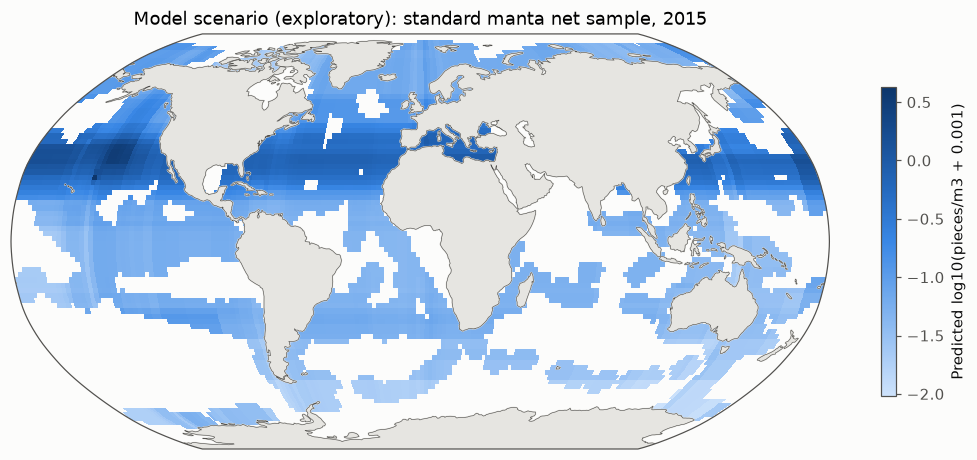

In [24]:
lat_centres, lon_centres = np.arange(-79, 90, 2.0), np.arange(-179, 180, 2.0)
lat_grid, lon_grid = np.meshgrid(lat_centres, lon_centres, indexing="ij")
cells = pd.DataFrame({"lat": lat_grid.ravel(), "lon": lon_grid.ravel()}).assign(
    year=2015, log_mesh=np.log10(0.333), log_depth=0.0, method_family="surface net", method="manta net"
)
monthly = [
    final.predict(cells.assign(month_sin=np.sin(2 * np.pi * m / 12), month_cos=np.cos(2 * np.pi * m / 12))[CATBOOST_FEATURES])
    for m in range(1, 13)
]
surface = np.mean(monthly, axis=0)
surface_nets = df[df.method_family == "surface net"]
distance_km = BallTree(np.radians(surface_nets[["lat", "lon"]]), metric="haversine").query(np.radians(cells[["lat", "lon"]]))[0][:, 0] * 6371
surface[distance_km > 500] = np.nan

fig = plt.figure(figsize=(12, 5.2))
ax = fig.add_subplot(projection=ccrs.Robinson())
ax.set_global()
mesh = ax.pcolormesh(np.arange(-180, 181, 2.0), np.arange(-80, 91, 2.0), surface.reshape(lat_grid.shape),
                     cmap=SEQUENTIAL, transform=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, color="#e6e5e1", zorder=2)
ax.coastlines(linewidth=0.4, color=INK_MUTED, zorder=3)
fig.colorbar(mesh, ax=ax, shrink=0.7, label="Predicted log10(pieces/m3 + 0.001)")
ax.set_title("Model scenario (exploratory): standard manta net sample, 2015")
plt.show()

The horizontal banding comes from the trees splitting on latitude. The high band between 20° and 45° N
and the high Mediterranean values agree with published accumulation patterns, but those are also the
areas sampled most densely by the studies with the highest counts, so the map cannot tell the two apart.

## 9. Conclusions

1. **Random-split accuracy is mostly study recognition.** Tree ensembles reach R² ≈ 0.74 on random folds.
   With whole studies held out, the best model (CatBoost) reaches a pooled R² of 0.25, every model has a
   negative fold mean, and on the 2015-onwards holdout every model is near zero. Study identity alone
   explains 72% of the target variance (ICC), and on random folds the study label adds nothing to
   location and date, because those already identify the cruise.
2. **Some information does transfer.** Under grouped CV, about two thirds of CatBoost's predictions are within
   one order of magnitude of the measurement, and the full feature set beats both location-and-time and
   protocol features on their own.
3. **The ranking of models depends on the split.** Random forest, XGBoost and the hurdle model are level
   with CatBoost and LightGBM on random folds and fall behind on new studies. The OLS and mixed-model
   fits are unstable on this data, for reasons traced to collinear sampling fields and unseen study
   offsets.
4. **Tuning does not close the gap.** The genetic algorithm beat an equal-budget random search on the
   development folds (RMSE 0.883 against 0.907) and moved the holdout score very little.
5. **SHAP shows study artifacts directly.** The negative effect of the finest mesh and the
   three-orders-of-magnitude effect of a 5-row method label are properties of individual studies, not of
   the ocean.

The practical message for anyone publishing a model on aggregated microplastic data is to report grouped
validation. A random-split R² mostly measures recognition of studies the model has already seen.

### Changes from the synopsis

- The target is `log10(conc + 0.001)`, not `log1p`, because `log1p` leaves 75% of the data almost
  untransformed (section 2.1).
- The modelling set is the 15,534 ocean-water records, not all 16,205 pieces/m3 records. The 671 beach
  records in pieces/m3 measure sand.
- Studies are grouped by publication (DOI) rather than accession. One publication was archived as two
  accessions.
- Medium is not a feature, because only ocean water remains after filtering.
- The GAMM is approximated with statsmodels `MixedLM` with natural cubic spline bases and a random
  intercept per study. Its smoothness is fixed by the basis size, not estimated by penalised likelihood as
  in R's `mgcv`.
- Added beyond the synopsis: a study-mean reference, a spatial kNN baseline, LightGBM, an XGBoost hurdle
  model for the zeros, a random-search control for the GA, feature-group ablations, and a seen/unseen
  breakdown of the chronological holdout.

### Next steps

- Add oceanographic covariates (sea surface temperature, surface currents, distance to river mouths and
  coasts) by joining on latitude, longitude and date. These are the most plausible source of signal that
  transfers between studies.
- Use sampled water volume or tow length if they can be recovered from the source papers. Zeros from a
  short tow and zeros from a long one mean different things.
- Model the sediment (pieces/kg) and beach records separately, as the synopsis planned.